# Explorador de imputación 


In [1]:
# 1. CONFIGURACIÓN: modifica estas opciones y ejecuta todo.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATASET = "ishii"                 # "ishii" o "mmc2"
METABOLITO = "fum[c]"             # fum[c], pep[c], s7p[c], succ[c]
EXPERIMENTO = "perturbation"      # perturbation, real_patterns, analytical_series (solo Ishii)
POLITICA = "available"            # available o supported_plus_baseline
SOLO_CASOS_COMUNES = True         # comparar sobre los mismos casos aceptados por los tres
PATRON = None                     # para real_patterns: None = todos; o "P01", "P02", etc.
RUTA_PROYECTO = None              # opcional: r"C:\Users\TuUsuario\...\IPre_Normalizacion_Imputacion"

METHODS = ["SimpleImputer", "KNNImputer", "IterativeImputer"]
NAMES = {"SimpleImputer": "Mediana", "KNNImputer": "KNN", "IterativeImputer": "Iterative"}
COLORS = {"SimpleImputer": "#777777", "KNNImputer": "#16869b", "IterativeImputer": "#b5548c"}
LABELS = {"fum[c]":"Fumarato", "pep[c]":"PEP", "s7p[c]":"s7p", "succ[c]":"Succinato"}
assert DATASET in ("ishii", "mmc2")
assert METABOLITO in LABELS
assert POLITICA in ("available", "supported_plus_baseline")

if RUTA_PROYECTO:
    ROOT = Path(RUTA_PROYECTO).expanduser().resolve()
else:
    candidates = [Path.cwd(), Path.cwd()/"IPre_Normalizacion_Imputacion", Path.cwd().parent]
    ROOT = next((p for p in candidates if (p/"normalizacion").is_dir() and (p/"ejecutar_imputacion.py").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("No encuentro el proyecto. Coloca el notebook junto a ejecutar_imputacion.py o define RUTA_PROYECTO.")
RES = ROOT/"resultados"/DATASET
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Proyecto: {ROOT}\nBase seleccionada: {DATASET}\nResultados: {RES}")


Proyecto: c:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa
Base seleccionada: ishii
Resultados: c:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa\resultados\ishii


In [2]:
# Cargar las matrices y resultados de UNA sola base.
def leer_csv(path, index_col=None):
    if not path.is_file():
        raise FileNotFoundError(f"Falta {path}. Comprueba que usas la carpeta simplificada y que el análisis de {DATASET} fue ejecutado.")
    return pd.read_csv(path, index_col=index_col)

original = leer_csv(ROOT/"normalizacion"/f"matriz_{DATASET}_mM.csv", index_col=0)
ratios = leer_csv(ROOT/"normalizacion"/f"matriz_{DATASET}_R.csv", index_col=0)
pred = leer_csv(RES/"validacion/predicciones.csv")
metricas = leer_csv(RES/"validacion/metricas.csv")
reales = leer_csv(RES/"imputacion/candidatos_y_soporte.csv")
estadisticas = leer_csv(RES/"imputacion/estadisticas_antes_despues.csv")
mascaras = json.loads((RES/"validacion/mascaras.json").read_text(encoding="utf-8"))
manifest = json.loads((RES/"manifest.json").read_text(encoding="utf-8"))
assert manifest["dataset"] == DATASET
assert original.index.equals(ratios.index)
print(f"{len(original)} muestras × {len(original.columns)} metabolitos; {int(original.notna().sum().sum())} mediciones originales.")
print("Pruebas disponibles:", ", ".join(pred.experiment.unique()))
if DATASET == "mmc2":
    display(Markdown("**MMC2:** no hay prueba por serie analítica equivalente a Ishii. Glucosa se excluye como consulta de evaluación porque su valor está revelado en la referencia de normalización. Los resultados de esta base son exploratorios y se mantienen separados de Ishii."))


30 muestras × 7 metabolitos; 138 mediciones originales.
Pruebas disponibles: analytical_series, perturbation, real_patterns


## Datos originales: todavía no hay imputación

Cada fila representa una muestra o condición; cada columna, un metabolito.


,fum[c],pep[c],s7p[c],succ[c],pyr[c],akg[c],cit[c]
sample_id,,,,,,,
KO01,0.0563,0.0786,0.1360,0.1120,NaN,0.0372,NaN
KO02,0.0521,0.0275,0.0885,0.0589,0.135,0.0462,0.02480
KO03,0.0372,0.0188,0.0678,0.0549,0.258,NaN,0.03920
KO04,NaN,NaN,0.2100,0.1270,NaN,NaN,0.00162
KO05,0.0710,0.0130,0.8690,0.1080,NaN,NaN,0.02310
KO05x,NaN,NaN,2.6900,0.1790,NaN,NaN,0.00593
KO06,0.0869,0.0616,0.1800,0.0686,0.254,0.0469,0.04660
KO07,0.0648,0.0664,0.1460,0.0552,0.153,0.0366,0.03180
KO08,0.0862,0.0395,0.2720,0.0539,0.113,0.0520,0.05180


,observados,faltantes,media_mM,mediana_mM,SD_mM
fum[c],23,7,0.05927,0.05630,0.02175
pep[c],22,8,0.08240,0.07370,0.06176
s7p[c],29,1,0.34743,0.18000,0.54637
succ[c],27,3,0.07867,0.06860,0.03053
pyr[c],14,16,0.22229,0.23850,0.09485
akg[c],11,19,0.05248,0.04810,0.02177
cit[c],12,18,0.03516,0.03305,0.02334


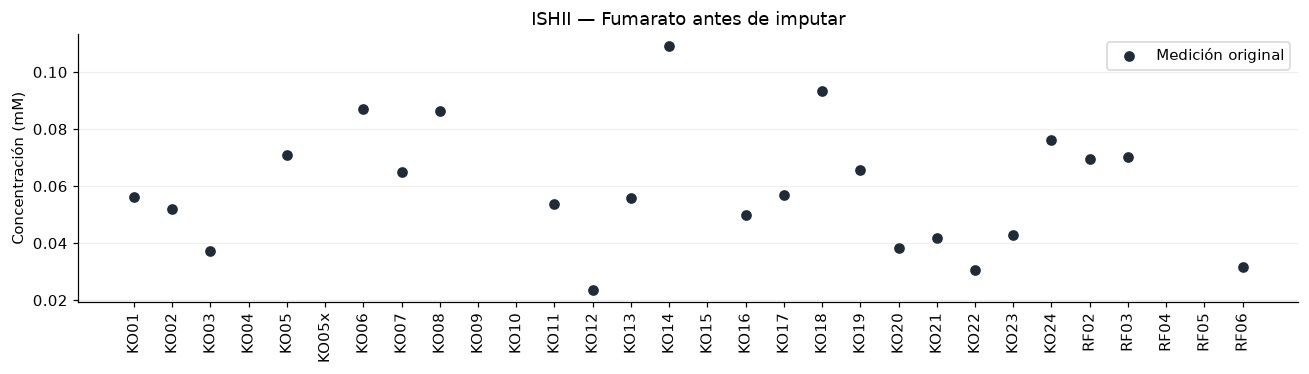

In [9]:
display(original.round(5))
resumen_original = pd.DataFrame({"observados": original.count(), "faltantes": original.isna().sum(),
    "media_mM": original.mean(), "mediana_mM": original.median(), "SD_mM": original.std(ddof=1)})
display(resumen_original.round(5))
fig, ax = plt.subplots(figsize=(12, 3.5))
x = np.arange(len(original))
ax.scatter(x, original[METABOLITO], color="#202b38", label="Medición original")
ax.set_xticks(x, original.index, rotation=90)
ax.set_ylabel("Concentración (mM)")
ax.set_title(f"{DATASET.upper()} — {LABELS[METABOLITO]} antes de imputar")
ax.grid(axis="y", alpha=.2)
ax.legend()
plt.tight_layout()
plt.show()


## Sección 1 — Evaluación: valor conocido ocultado frente a valor imputado


- `available`: incluye todos los candidatos finitos, incluso sustituciones generales o ajustes no convergentes.
- `supported_plus_baseline`: acepta solo predicciones con soporte de KNN e Iterative y conserva la mediana como referencia general. Esa excepción no convierte la mediana en una predicción individual con soporte.
- `SOLO_CASOS_COMUNES=True`: compara únicamente los casos aceptados por los tres métodos.

La tabla de cobertura siempre muestra los casos propios y comunes. Si la intersección está vacía, no se inventan comparaciones. 


In [4]:
# Mostrar qué oculta cada patrón real.
display(pd.DataFrame([{"patron": p["pattern_id"], "variables_ocultas": ", ".join(p["hidden"]),
    "objetivos_evaluados": ", ".join(p["score"]), "muestras_origen": ", ".join(p["source_samples"])}
    for p in mascaras["patterns"]]))

if EXPERIMENTO not in set(pred.experiment):
    raise ValueError(f"Prueba {EXPERIMENTO!r} no disponible para {DATASET}. Opciones: {list(pred.experiment.unique())}")
base = pred[(pred.experiment == EXPERIMENTO) & (pred.metabolite_id == METABOLITO)].copy()
if EXPERIMENTO == "real_patterns" and PATRON is not None:
    trials = {t["trial_id"] for t in mascaras["trials"] if t["pattern_id"] == PATRON}
    if not trials:
        raise ValueError(f"El patrón {PATRON} no tiene ensayos elegibles. Revisa la tabla de patrones.")
    base = base[base.trial_id.isin(trials)].copy()
base["aceptado"] = np.isfinite(base.estimate_mM)
if POLITICA == "supported_plus_baseline":
    base["aceptado"] &= (base.method == "SimpleImputer") | (base.support == "supported")
sets = {method: set(base.loc[(base.method==method)&base.aceptado, "case_id"]) for method in METHODS}
comunes = set.intersection(*(sets[m] for m in METHODS))
comparacion = base[base.aceptado].copy()
if SOLO_CASOS_COMUNES:
    comparacion = comparacion[comparacion.case_id.isin(comunes)].copy()
rows = []
for method in METHODS:
    propios = base[(base.method==method)&base.aceptado]
    seleccion = comparacion[comparacion.method==method]
    attempts = int((base.method==method).sum())
    rows.append({"metodo": NAMES[method], "intentos": attempts, "respuestas_propias": len(propios),
        "cobertura_propia_%": 100*len(propios)/attempts if attempts else np.nan,
        "casos_comunes": len(comunes), "casos_graficados": len(seleccion),
        "MAE_mM_seleccion": seleccion.absolute_error_mM.mean(), "MAE_R_seleccion": seleccion.absolute_error_R.mean()})
display(pd.DataFrame(rows).round(6))
if comparacion.empty:
    display(Markdown("**No hay casos aceptados para esta selección.** Puedes explorar `available` o desactivar casos comunes, indicando que las comparaciones podrían usar distintas celdas."))
else:
    display(comparacion[["sample_id", "trial_id", "method", "truth_mM", "estimate_mM", "absolute_error_mM", "support", "mechanism"]].round(6))


,patron,variables_ocultas,objetivos_evaluados,muestras_origen
0,P01,"fum[c], pep[c], pyr[c], akg[c]","fum[c], pep[c]","KO04, KO05x"
1,P02,"fum[c], pep[c], pyr[c], akg[c], cit[c]","fum[c], pep[c]","KO09, KO15, RF05"
2,P03,"fum[c], pep[c], s7p[c], succ[c], pyr[c], akg[c...","fum[c], pep[c], s7p[c], succ[c]",KO10
3,P04,"fum[c], pep[c], succ[c], pyr[c], akg[c], cit[c]","fum[c], pep[c], succ[c]",RF04
4,P05,"pep[c], akg[c], cit[c]",pep[c],KO21
5,P06,"succ[c], akg[c], cit[c]",succ[c],RF02


,metodo,intentos,respuestas_propias,cobertura_propia_%,casos_comunes,casos_graficados,MAE_mM_seleccion,MAE_R_seleccion
0,Mediana,23,23,100.0,23,23,0.017250,0.031464
1,KNN,23,23,100.0,23,23,0.022097,0.040305
2,Iterative,23,23,100.0,23,23,0.022466,0.040978


,sample_id,trial_id,method,truth_mM,estimate_mM,absolute_error_mM,support,mechanism
303,KO01,perturbation:KO01:fum[c],SimpleImputer,0.0563,0.056350,0.000050,training_only,training_median
304,KO01,perturbation:KO01:fum[c],KNNImputer,0.0563,0.076133,0.019833,supported,neighbor_mean
305,KO01,perturbation:KO01:fum[c],IterativeImputer,0.0563,0.085303,0.029003,supported,conditional_iterative_model_with_internal_fills
315,KO02,perturbation:KO02:fum[c],SimpleImputer,0.0521,0.056550,0.004450,training_only,training_median
316,KO02,perturbation:KO02:fum[c],KNNImputer,0.0521,0.060533,0.008433,supported,neighbor_mean
...,...,...,...,...,...,...,...,...
574,RF03,perturbation:RF03:fum[c],KNNImputer,0.0702,0.040433,0.029767,supported,neighbor_mean
575,RF03,perturbation:RF03:fum[c],IterativeImputer,0.0702,0.035433,0.034767,supported,conditional_iterative_model_with_internal_fills
594,RF06,perturbation:RF06:fum[c],SimpleImputer,0.0315,0.056100,0.024600,training_only,training_median
595,RF06,perturbation:RF06:fum[c],KNNImputer,0.0315,0.062200,0.030700,supported,neighbor_mean


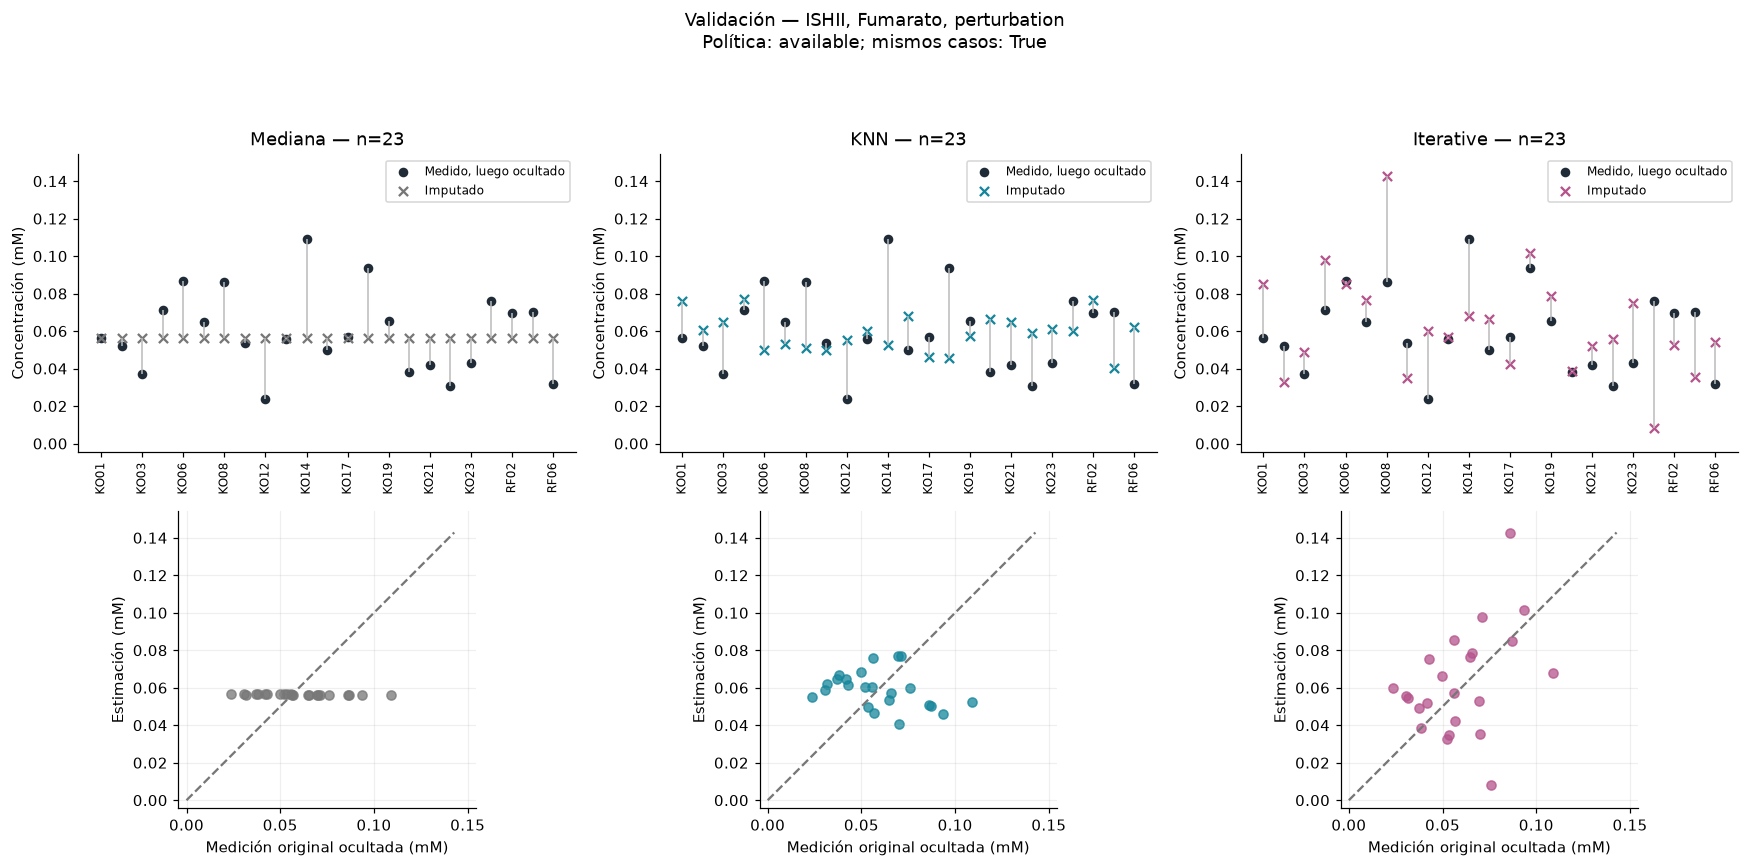

In [5]:
# Dos perspectivas de los mismos casos: comparación pareada y dispersión real vs estimado.
if not comparacion.empty:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    maximo = max(comparacion.truth_mM.max(), comparacion.estimate_mM.max(), .001)
    for j, method in enumerate(METHODS):
        d = comparacion[comparacion.method==method].sort_values("case_id")
        ax = axes[0,j]
        xx = np.arange(len(d))
        ax.vlines(xx, d.truth_mM, d.estimate_mM, color="#bbbbbb", lw=1)
        ax.scatter(xx, d.truth_mM, color="#202b38", s=28, label="Medido, luego ocultado")
        ax.scatter(xx, d.estimate_mM, color=COLORS[method], marker="x", s=36, label="Imputado")
        labels = [f"{r.sample_id}/{r.trial_id.split(':')[-1]}" if EXPERIMENTO=="real_patterns" else r.sample_id for r in d.itertuples()]
        step = max(1, int(np.ceil(len(d)/18)))
        ax.set_xticks(xx[::step], labels[::step], rotation=90, fontsize=8)
        ax.set_title(f"{NAMES[method]} — n={len(d)}")
        ax.set_ylabel("Concentración (mM)")
        ax.set_ylim(-.03*maximo, 1.08*maximo)
        ax.legend(fontsize=8)
        ax = axes[1,j]
        ax.scatter(d.truth_mM, d.estimate_mM, color=COLORS[method], alpha=.75)
        ax.plot([0,maximo], [0,maximo], "--", color="#777777")
        ax.set(xlabel="Medición original ocultada (mM)", ylabel="Estimación (mM)",
               xlim=(-.03*maximo,1.08*maximo), ylim=(-.03*maximo,1.08*maximo))
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=.2)
    fig.suptitle(f"Validación — {DATASET.upper()}, {LABELS[METABOLITO]}, {EXPERIMENTO}\nPolítica: {POLITICA}; mismos casos: {SOLO_CASOS_COMUNES}")
    plt.tight_layout(rect=(0,0,1,.93))
    plt.show()


In [6]:
# Estadísticas de las verdades ocultadas y sus estimaciones SOBRE LOS CASOS EVALUADOS.
# No se confunden con estadísticas de toda la cohorte ni de los huecos reales.
def describir(values):
    values = pd.Series(values).dropna()
    mean, sd = values.mean(), values.std(ddof=1)
    status = "n<2" if len(values)<2 else "media no positiva o cercana a cero" if mean<=1e-12 else "interpretable"
    return {"n":len(values), "media_mM":mean, "mediana_mM":values.median(), "SD_mM":sd,
            "IQR_mM":values.quantile(.75)-values.quantile(.25),
            "CV_%":100*sd/mean if status=="interpretable" else np.nan, "estado_CV":status}
resumen_validacion = []
for method in METHODS:
    d = comparacion[comparacion.method==method]
    for tipo, columna in [("Mediciones ocultadas", "truth_mM"), ("Estimaciones", "estimate_mM")]:
        resumen_validacion.append({"metodo":NAMES[method], "datos":tipo, **describir(d[columna])})
display(pd.DataFrame(resumen_validacion).round(6))


,metodo,datos,n,media_mM,mediana_mM,SD_mM,IQR_mM,CV_%,estado_CV
0,Mediana,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
1,Mediana,Estimaciones,23,0.056307,0.056100,0.000224,0.000450,0.398300,interpretable
2,KNN,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
3,KNN,Estimaciones,23,0.059075,0.059833,0.009910,0.013150,16.774510,interpretable
4,Iterative,Mediciones ocultadas,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
5,Iterative,Estimaciones,23,0.063048,0.056995,0.028423,0.031967,45.081743,interpretable


## Sección 2 — Candidatos reales: completar huecos que no tenían medición

El gráfico distingue valores medidos de imputados. Las estadísticas se calculan sobre todas las muestras de la base seleccionada, omitiendo los valores pendientes. 


In [7]:
# Reconstruir en memoria las matrices a mostrar; nunca se escriben al disco.
r = reales.copy()
r["aceptado"] = np.isfinite(r.estimate_mM)
if POLITICA == "supported_plus_baseline":
    r["aceptado"] &= (r.method == "SimpleImputer") | (r.support == "supported")
real_sets = {m:set(zip(g.loc[g.aceptado,"sample_id"],g.loc[g.aceptado,"metabolite_id"]))
             for m in METHODS for g in [r[r.method==m]]}
real_common = set.intersection(*(real_sets[m] for m in METHODS))
matrices = {}
for method in METHODS:
    matrix = original.copy()
    elegibles = real_common if SOLO_CASOS_COMUNES else real_sets[method]
    for row in r[r.method==method].itertuples():
        if (row.sample_id,row.metabolite_id) in elegibles:
            assert pd.isna(original.loc[row.sample_id,row.metabolite_id])
            matrix.loc[row.sample_id,row.metabolite_id] = row.estimate_mM
    np.testing.assert_array_equal(matrix.to_numpy()[original.notna()], original.to_numpy()[original.notna()])
    matrices[method] = matrix
print(f"Candidatos originales en los cuatro objetivos: {len(r)//len(METHODS)}; celdas comunes aceptadas: {len(real_common)}")
display(r[r.metabolite_id==METABOLITO][["sample_id","method","estimate_mM","aceptado","support","mechanism"]].round(6))
if not original[METABOLITO].isna().any():
    display(Markdown("**El metabolito seleccionado no tiene huecos reales en esta base.** Su gráfico y estadísticas después conservan las mediciones originales."))


Candidatos originales en los cuatro objetivos: 19; celdas comunes aceptadas: 19


,sample_id,method,estimate_mM,aceptado,support,mechanism
0,KO04,SimpleImputer,0.056300,True,training_only,training_median
2,KO04,KNNImputer,0.078300,True,limited_support,neighbor_mean
4,KO04,IterativeImputer,0.044900,True,supported,conditional_iterative_model_with_internal_fills
6,KO05x,SimpleImputer,0.056100,True,training_only,training_median
8,KO05x,KNNImputer,0.076167,True,supported,neighbor_mean
10,KO05x,IterativeImputer,0.145357,True,supported,conditional_iterative_model_with_internal_fills
12,KO09,SimpleImputer,0.056300,True,training_only,training_median
14,KO09,KNNImputer,0.052633,True,limited_support,neighbor_mean
16,KO09,IterativeImputer,0.058676,True,supported,conditional_iterative_model_with_internal_fills
18,KO10,SimpleImputer,0.056300,True,training_only,training_median


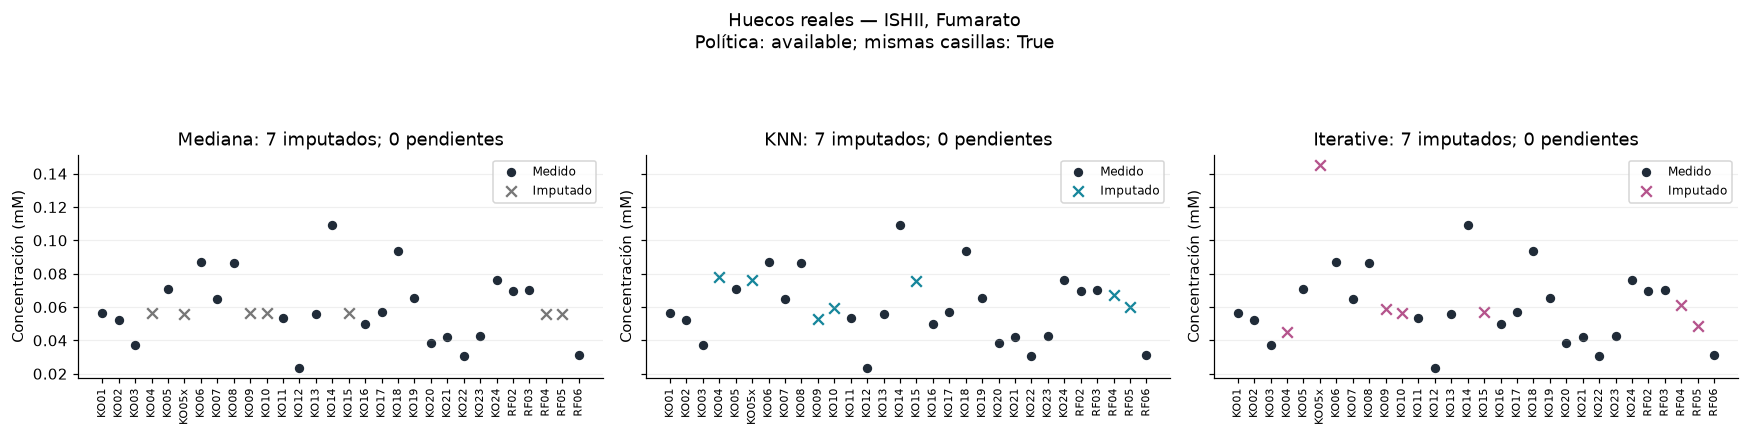

,metodo,etapa,total,observados,imputados,pendientes,n,media_mM,mediana_mM,SD_mM,IQR_mM,CV_%,estado_CV
0,Mediana,Antes,30,23,0,7,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
1,Mediana,Después,30,23,7,0,30,0.058553,0.056300,0.018988,0.018225,32.428764,interpretable
2,KNN,Antes,30,23,0,7,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
3,KNN,Después,30,23,7,0,30,0.061087,0.059766,0.019766,0.024050,32.356591,interpretable
4,Iterative,Antes,30,23,0,7,23,0.059265,0.056300,0.021748,0.028250,36.696821,interpretable
5,Iterative,Después,30,23,7,0,30,0.061173,0.056538,0.024948,0.024226,40.781683,interpretable


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
x = np.arange(len(original))
observed = original[METABOLITO].notna()
for ax, method in zip(axes, METHODS):
    column = matrices[method][METABOLITO]
    imputed = ~observed & column.notna()
    pending = ~observed & column.isna()
    ax.scatter(x[observed], original.loc[observed,METABOLITO], color="#202b38", s=26, label="Medido")
    ax.scatter(x[imputed], column[imputed], color=COLORS[method], marker="x", s=48, label="Imputado")
    ax.set_xticks(x, original.index, rotation=90, fontsize=7)
    ax.set_title(f"{NAMES[method]}: {int(imputed.sum())} imputados; {int(pending.sum())} pendientes")
    ax.set_ylabel("Concentración (mM)")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"Huecos reales — {DATASET.upper()}, {LABELS[METABOLITO]}\nPolítica: {POLITICA}; mismas casillas: {SOLO_CASOS_COMUNES}")
plt.tight_layout(rect=(0,0,1,.88))
plt.show()

rows=[]
for method in METHODS:
    for etapa, matrix in [("Antes", original), ("Después", matrices[method])]:
        column = matrix[METABOLITO]
        n_observed = int(original[METABOLITO].count())
        rows.append({"metodo":NAMES[method], "etapa":etapa, "total":len(original), "observados":n_observed,
                     "imputados":int(column.count())-n_observed, "pendientes":int(column.isna().sum()), **describir(column)})
display(pd.DataFrame(rows).round(6))
